## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [8]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Justin Diamond

**Date:** 10/19/26

## Q1

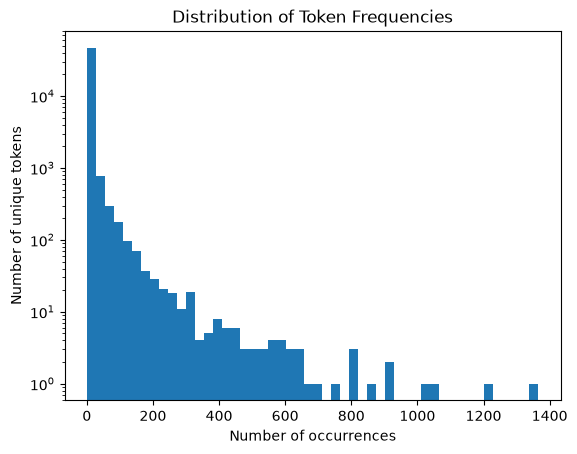

In [9]:
import matplotlib.pyplot as plt

counts = list(token_count.values())

plt.hist(counts, bins=50)
plt.xlabel("Number of occurrences")
plt.ylabel("Number of unique tokens")
plt.title("Distribution of Token Frequencies")
plt.yscale("log")
plt.show()

The token frequencies are strongly right-skewed. Most tokens occur very rarely, while a small number occur hundreds or thousands of times. For example, the median frequency is 1, and about 60% of unique tokens occur only once, while the most common token occurs 1,365 times. 

## Q2

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

data = pd.read_parquet("data/Phishing_clean.parquet")

X = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training R²:", model.score(X_train, y_train))
print("Test R²:", model.score(X_test, y_test))

Training R²: 0.7670143724934355
Test R²: 0.6658718438847919


In [11]:
coefficients = pd.Series(model.coef_, index=X.columns)
largest = coefficients.abs().sort_values(ascending=False).head(10)

print(largest)

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
gray;                0.574480
dtype: float64


The model has a training R^2 of 0.767 and a test R2 of 0.666. The lower test score suggests some overfitting. The tokens with the largest absolute coefficients are intervention, localized and thermal. These tokens have the strongest influence on the model’s predictions.

## Q3

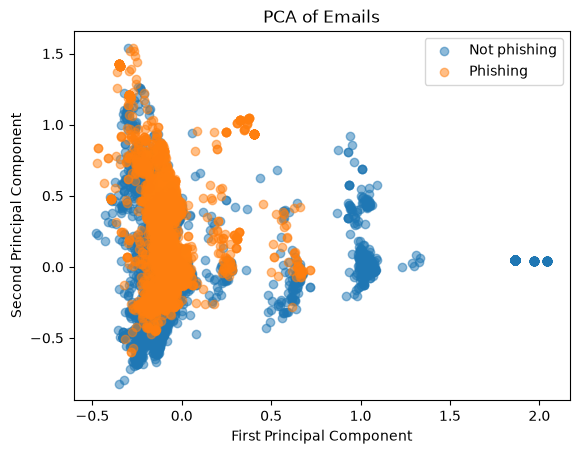

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label="Not phishing",
    alpha=0.5
)

plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label="Phishing",
    alpha=0.5
)

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("PCA of Emails")
plt.legend()
plt.show()

The phishing and non-phishing emails are overlapped mostly, so the first two components do not completely separate the two groups. However, most phishing emails are near the left and centre of the plot, while the clusters farther to the right contain mostly non-phishing emails

## Q4 

In [13]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

print("PCA training R²:", pca_model.score(X_train_pca, y_train))
print("PCA test R²:", pca_model.score(X_test_pca, y_test))

PCA training R²: 0.7662326827745848
PCA test R²: 0.6683390643101166


The PCA regression has a training \(R^2\) of 0.766 and a test \(R^2\) of 0.668. The original regression had scores of 0.767 and 0.666, so the models perform almost the same. PCA slightly lowers the training score and improves the test score, suggesting that the removed items that contained little useful predictive information. 

## Q5

Using principal components reduces the number of variables while keeping most of the information in the original data. This can make the regression faster, reduce noise, and produce similar test performance with fewer predictors.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [14]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]